In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd

Simulation with N_gbn=61, delta=0.005, dtmax=0.01
 Conducting simulation w/o PU dislocations, as tau0=0
 Starting iteration for T, tau0, D2, Lgb, Ngbn   500.00000000000000        0.0000000000000000        1.0000000000000000       0.29999999999999999               61
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     2000000   9.9999999999999985E-003   1.9999960003732394E-002   1.3476839049983892E-011   2.2833688292140553E-006           0           1  -1.7976931348623157E+308


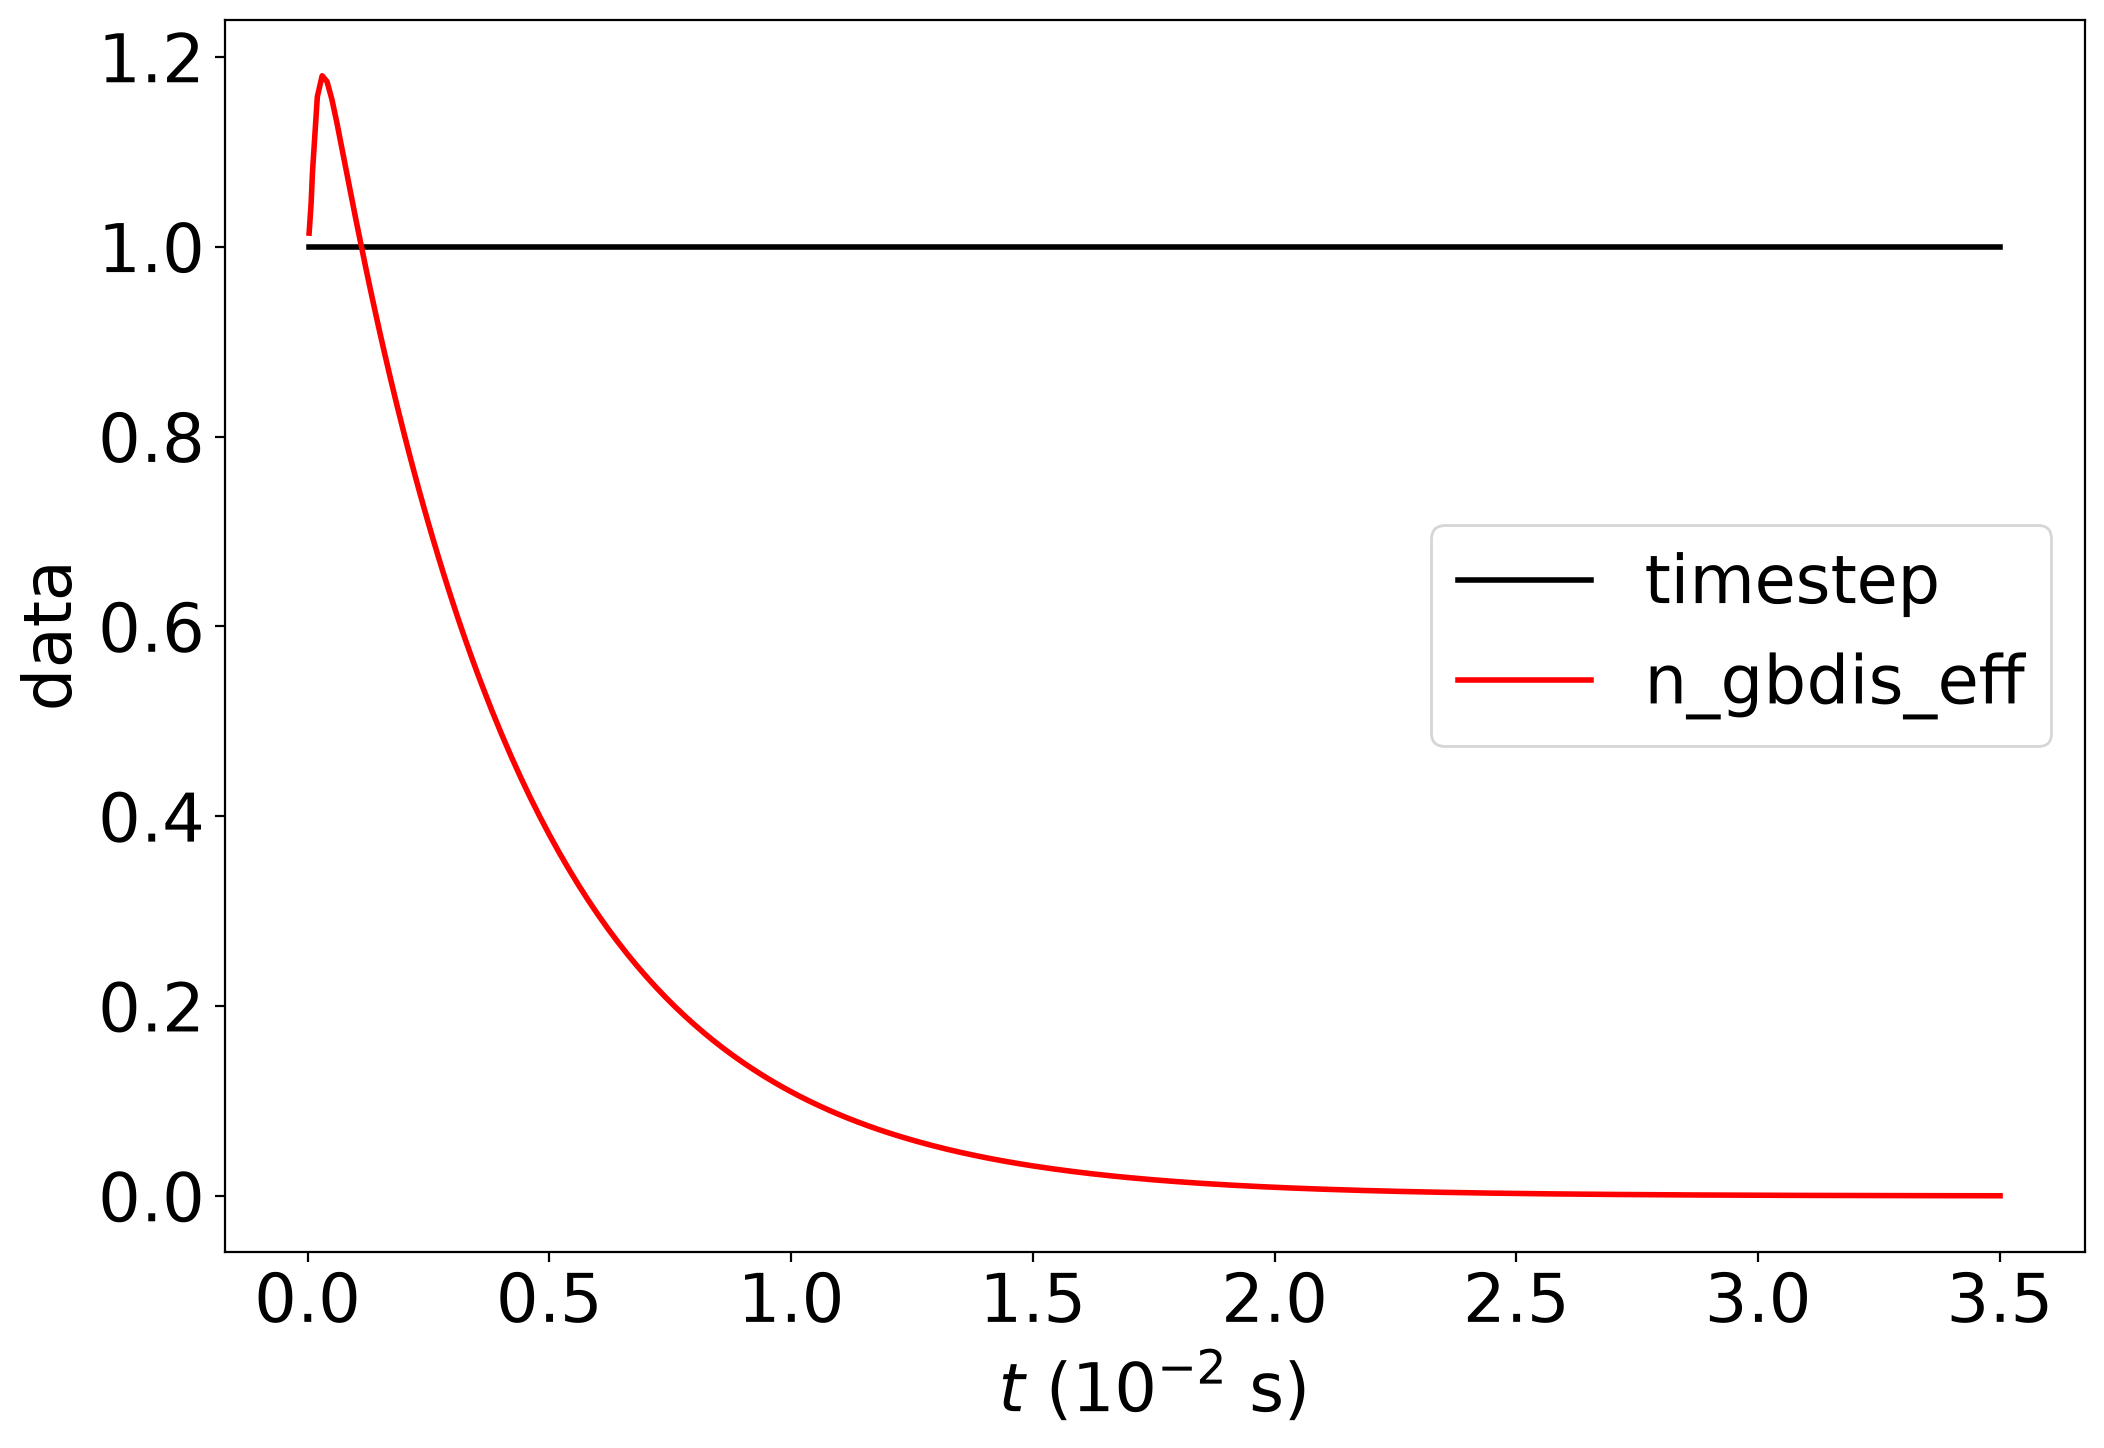

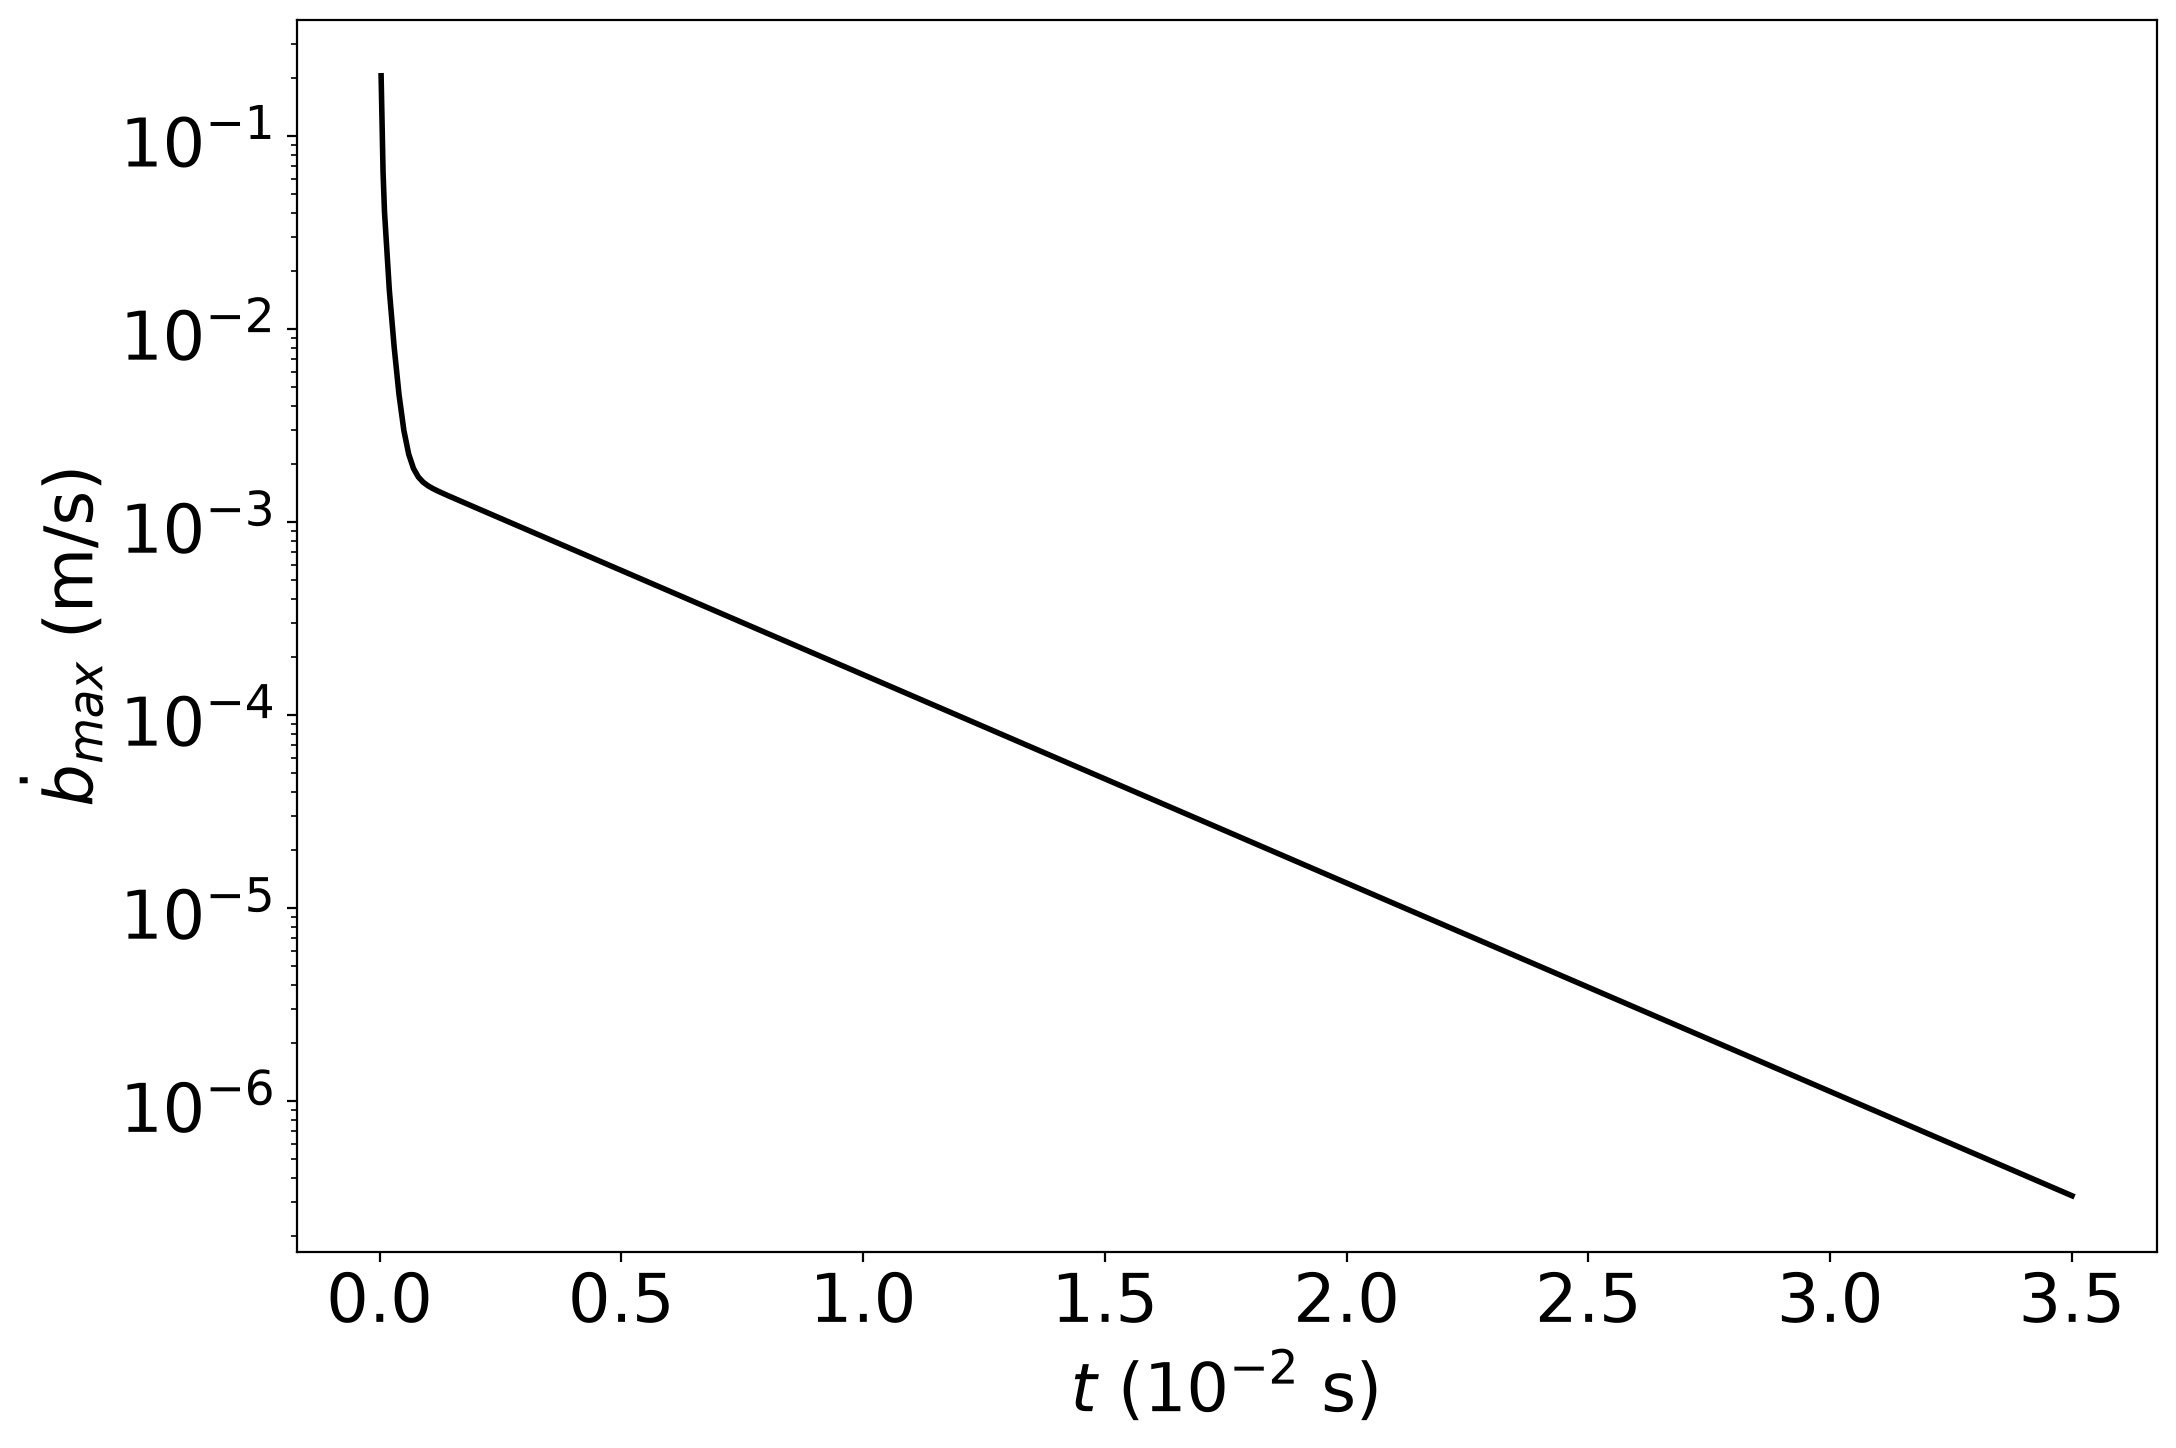

In [9]:
#define system parameters
maxout = 1000
temp = 500.0
tau0 = 0.0
lgb = 0.3
grain_size = 1.0
tfin = 3.5e4
niter = 200_000_000
delta = 0.005
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 1.e-2  # 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
print(f"Simulation with N_gbn={ngbn}, delta={delta}, dtmax={dtmax}")
gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=grain_size,
                   tfin=tfin, niter=niter, maxout=maxout,
                   dtmax=dtmax, lambda_=0.001, Z=2.0,
                   screenout=True)
gbdd.run_sim()
gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
gbdd.plot_time_series('max_bdot')

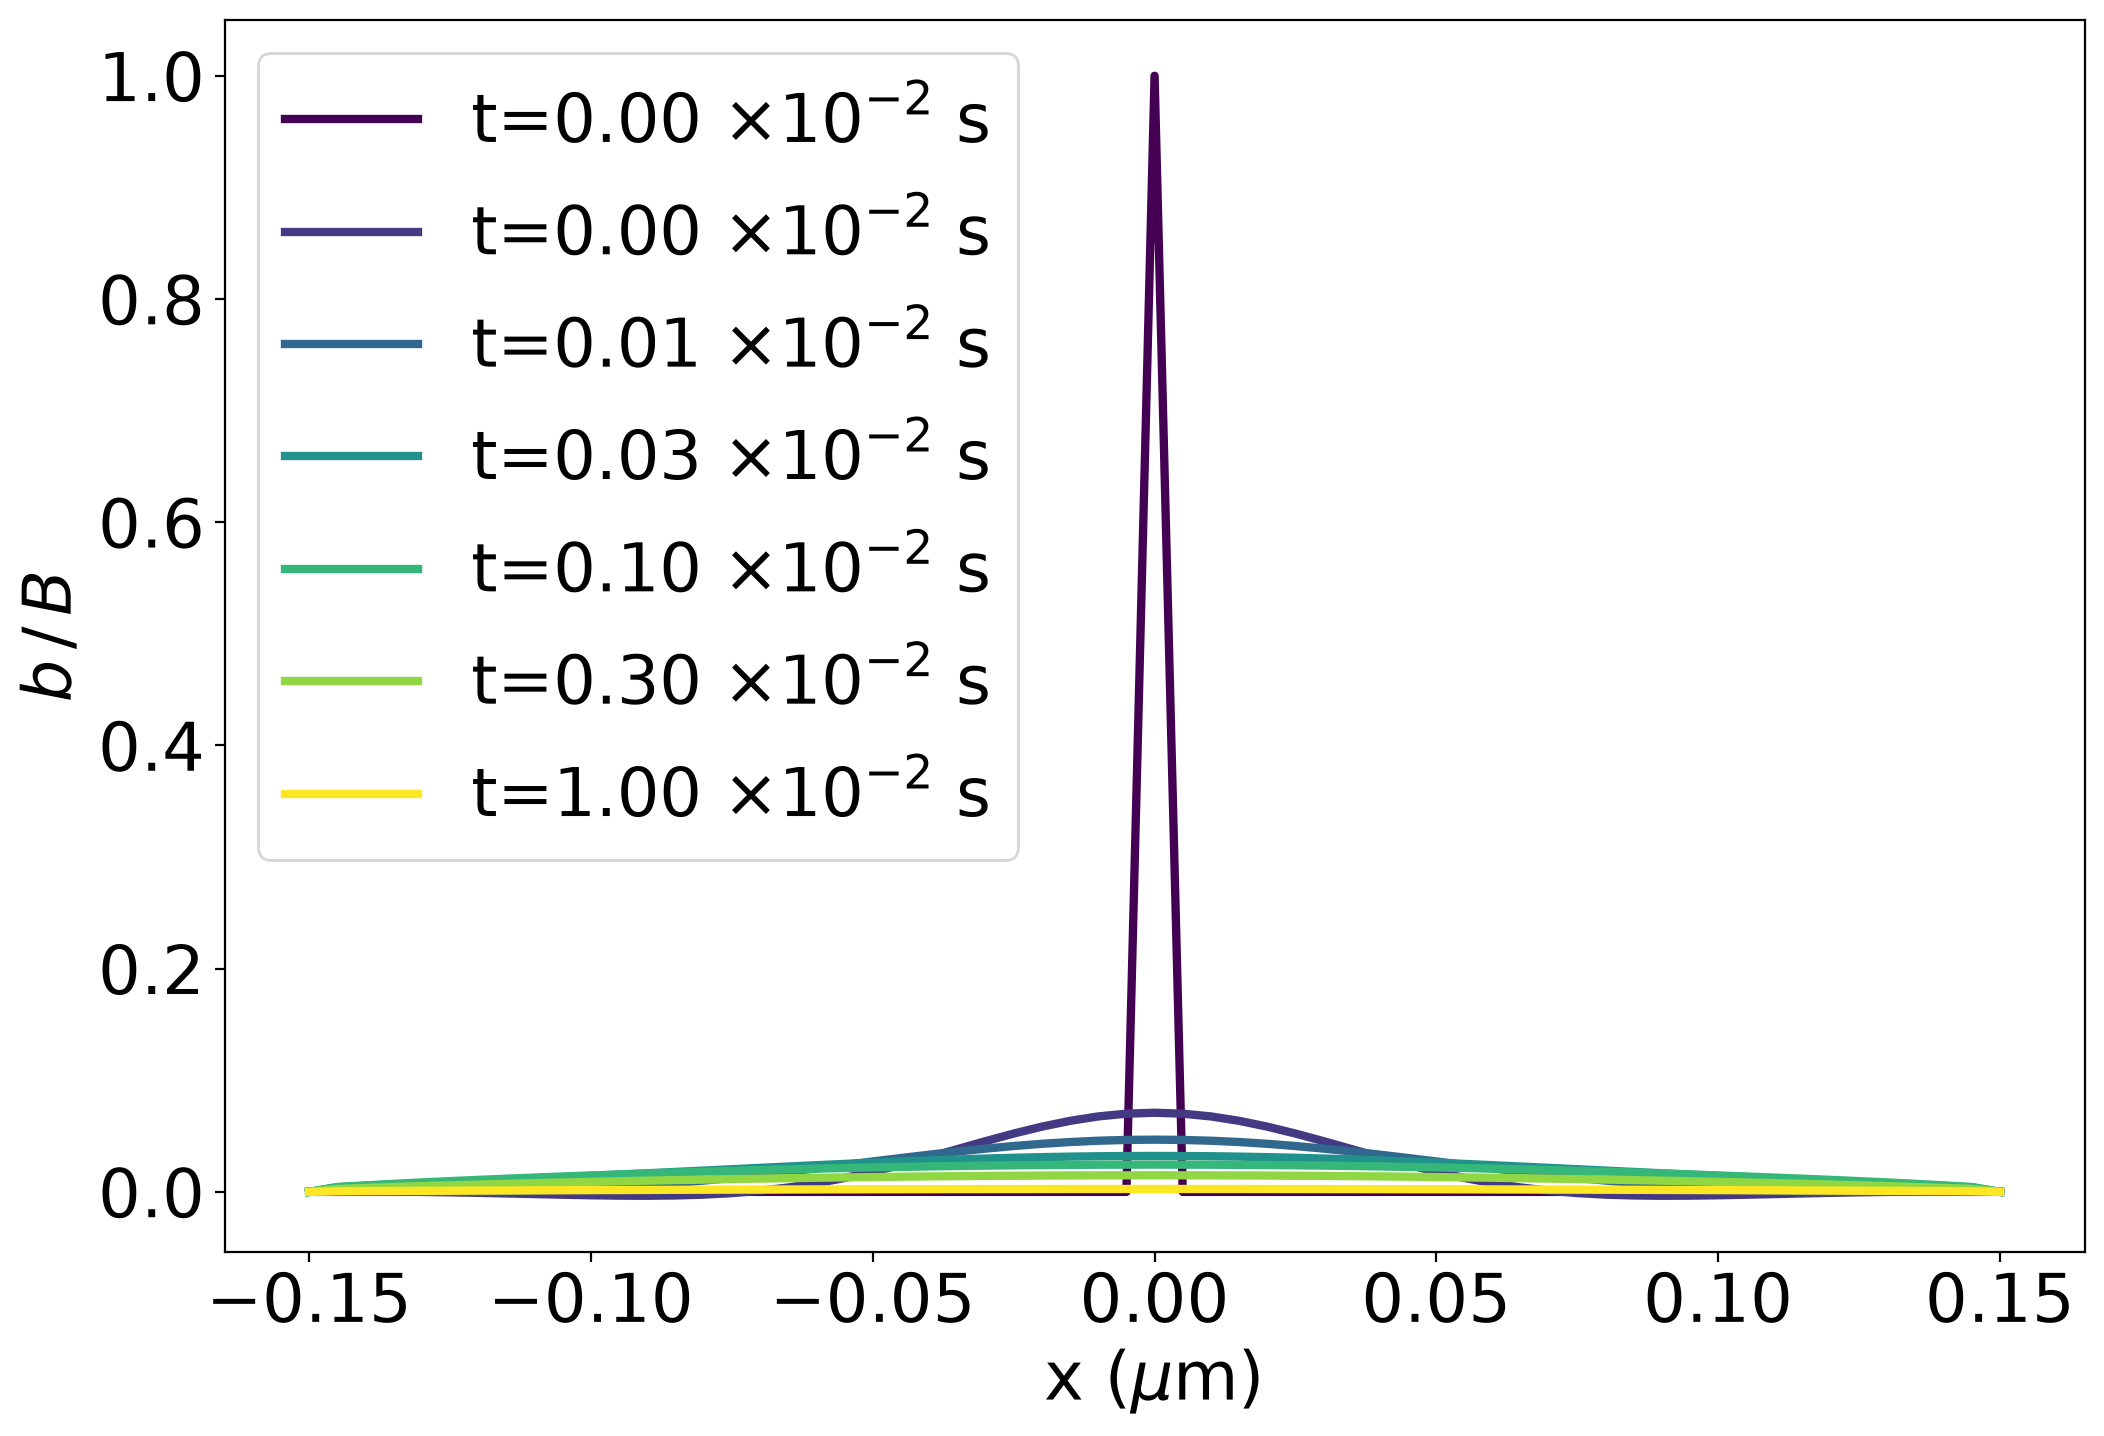

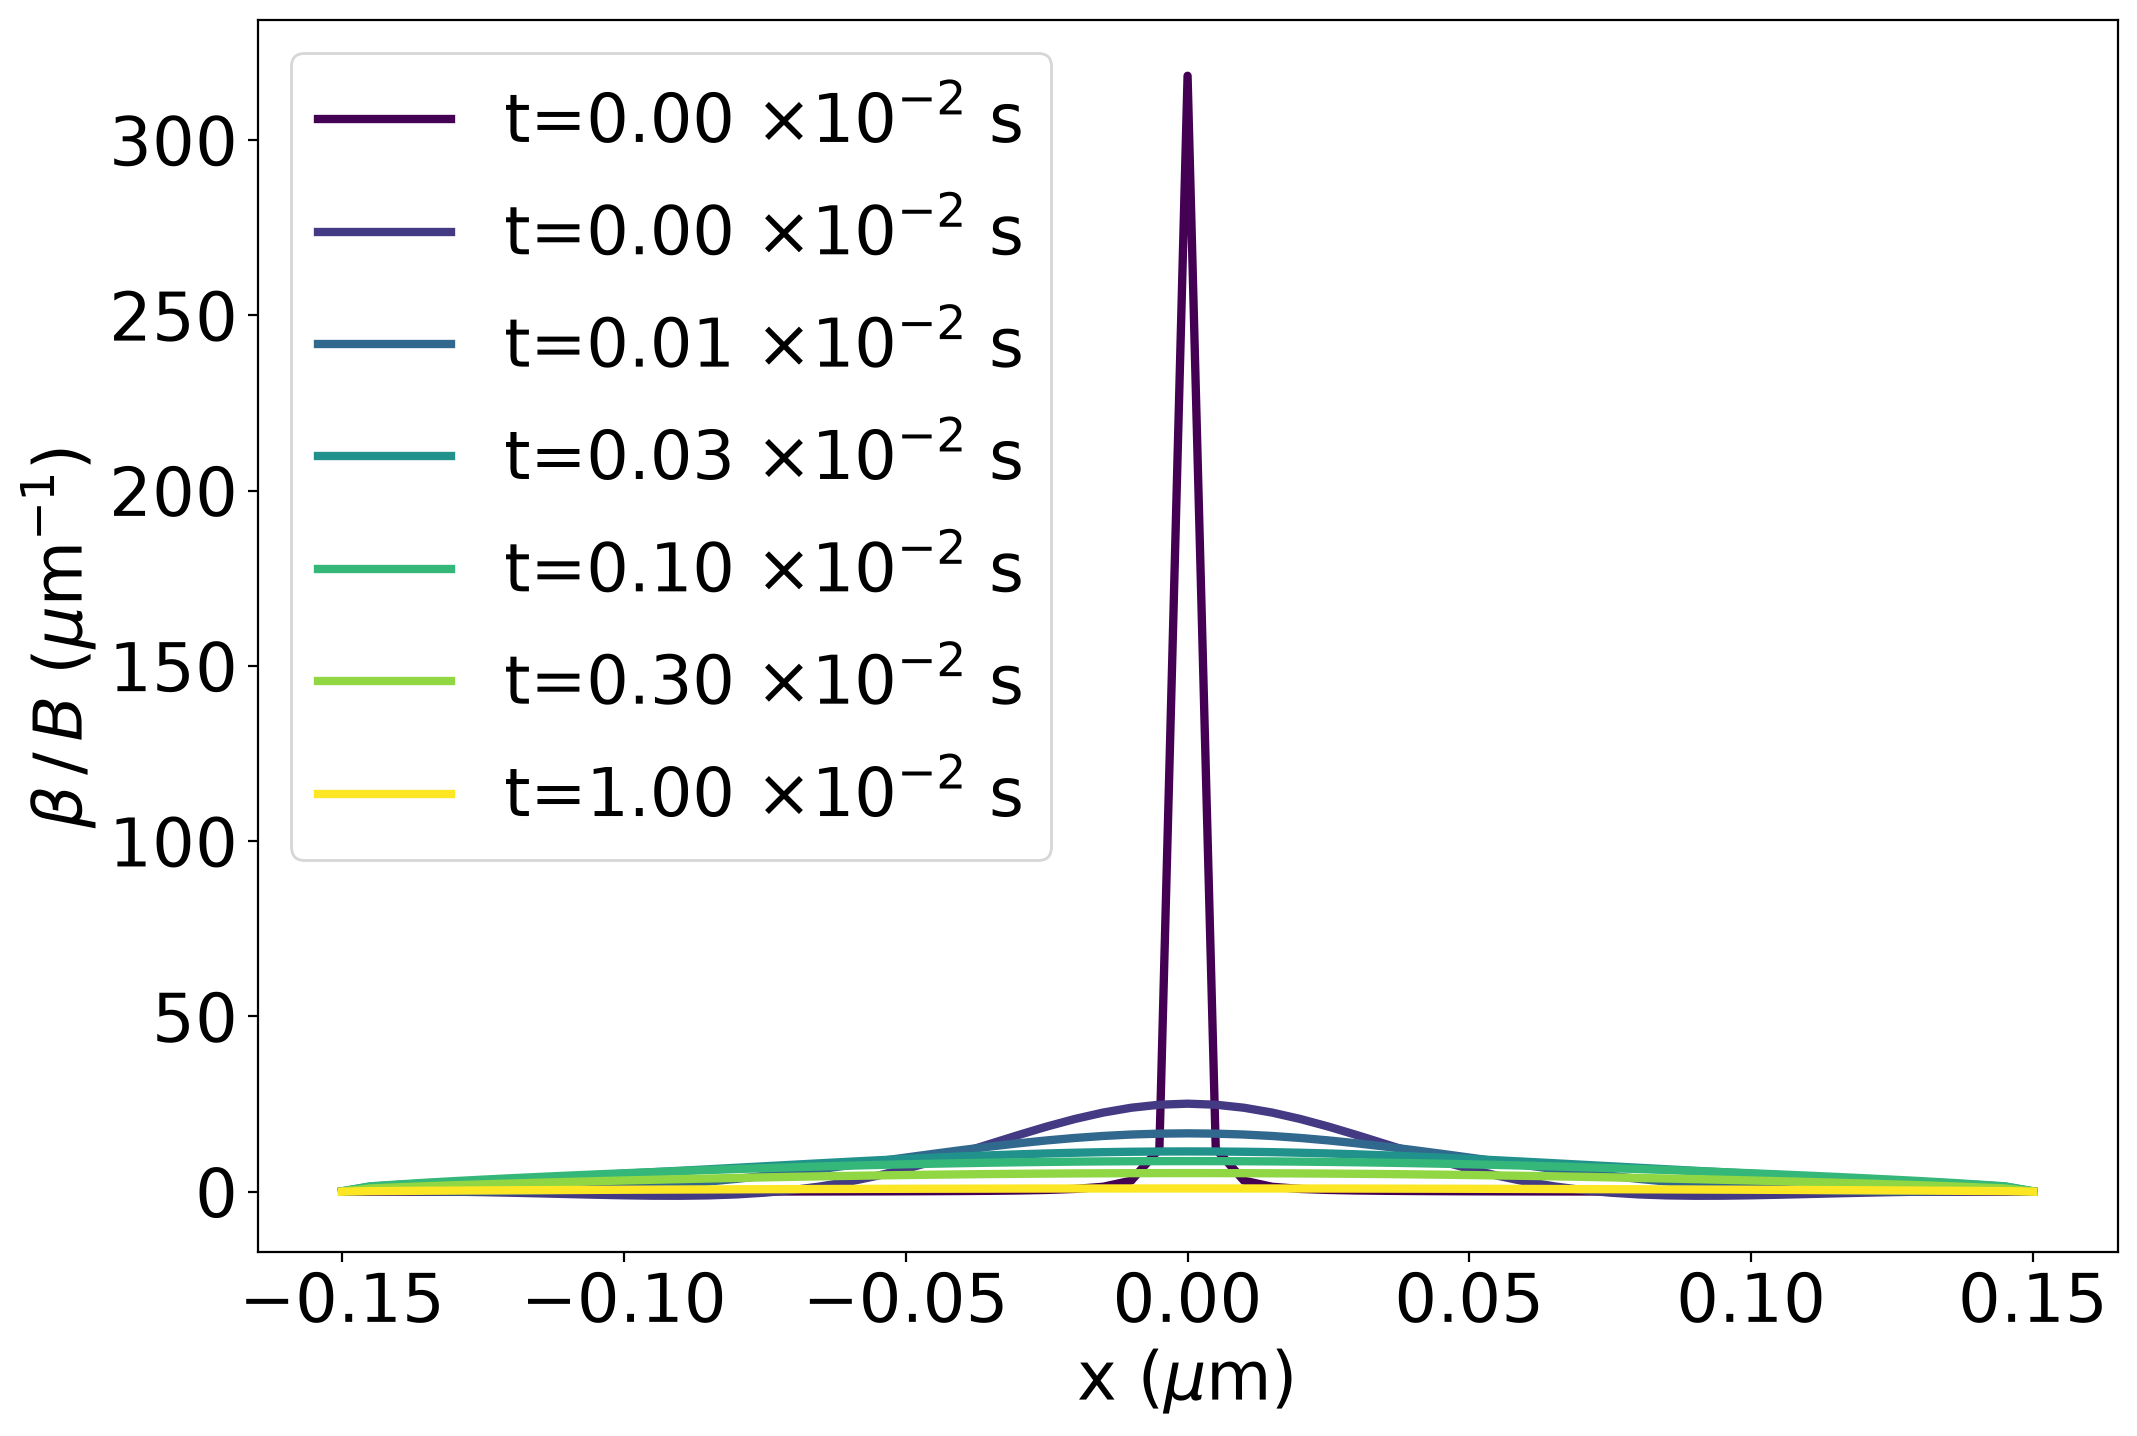

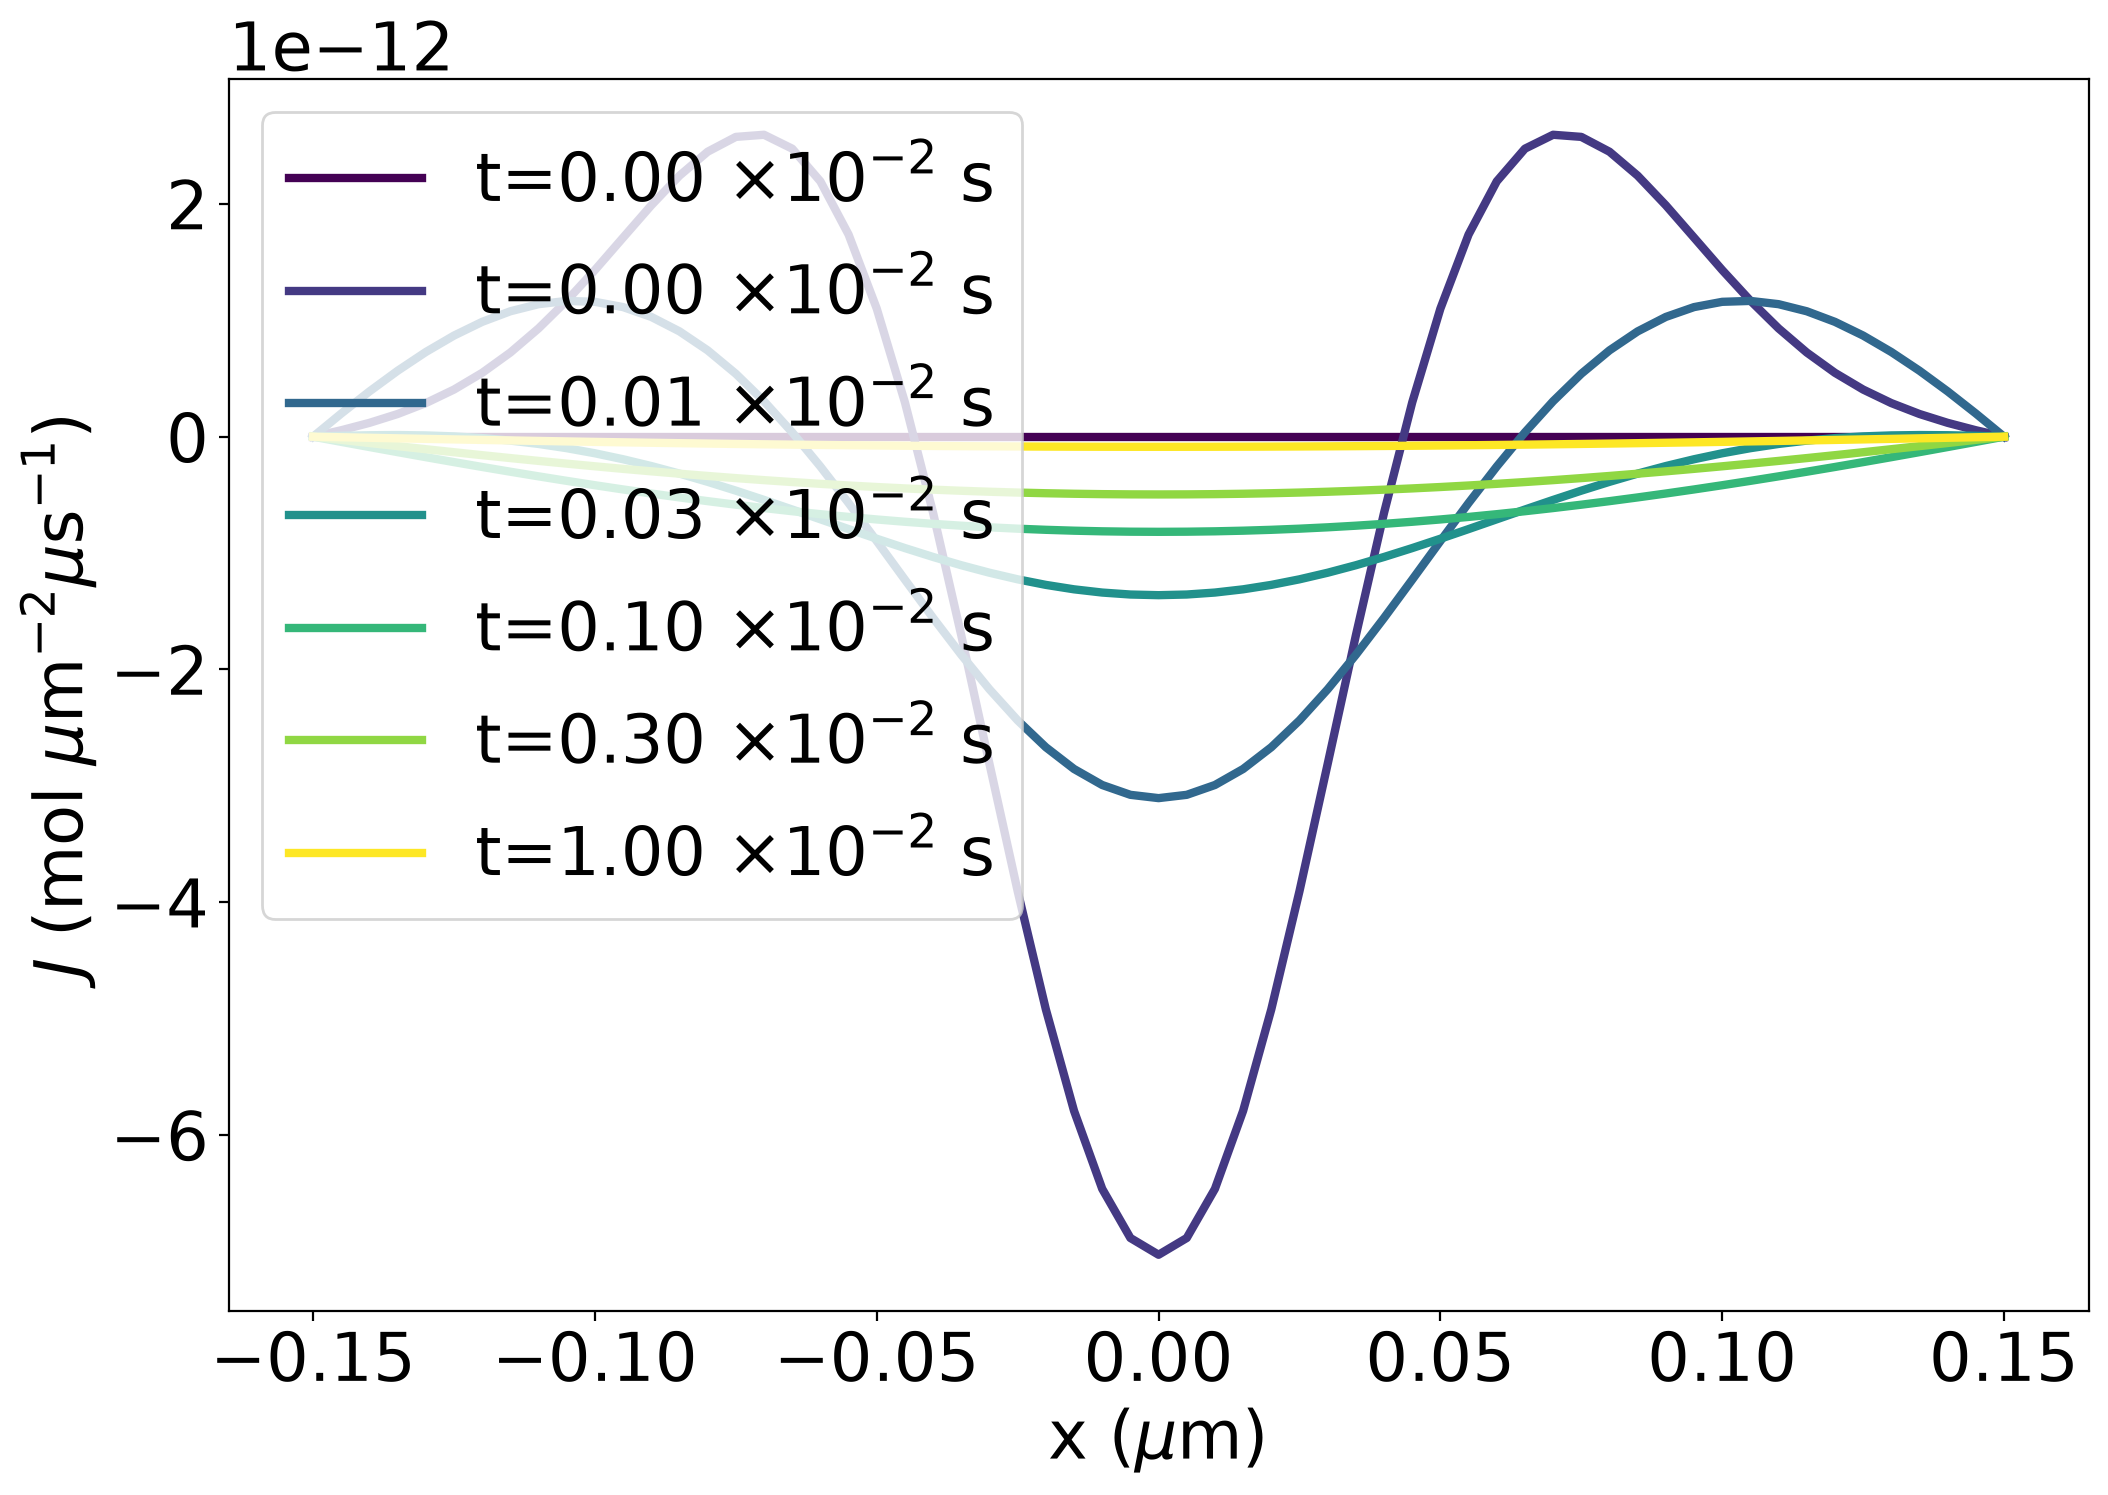

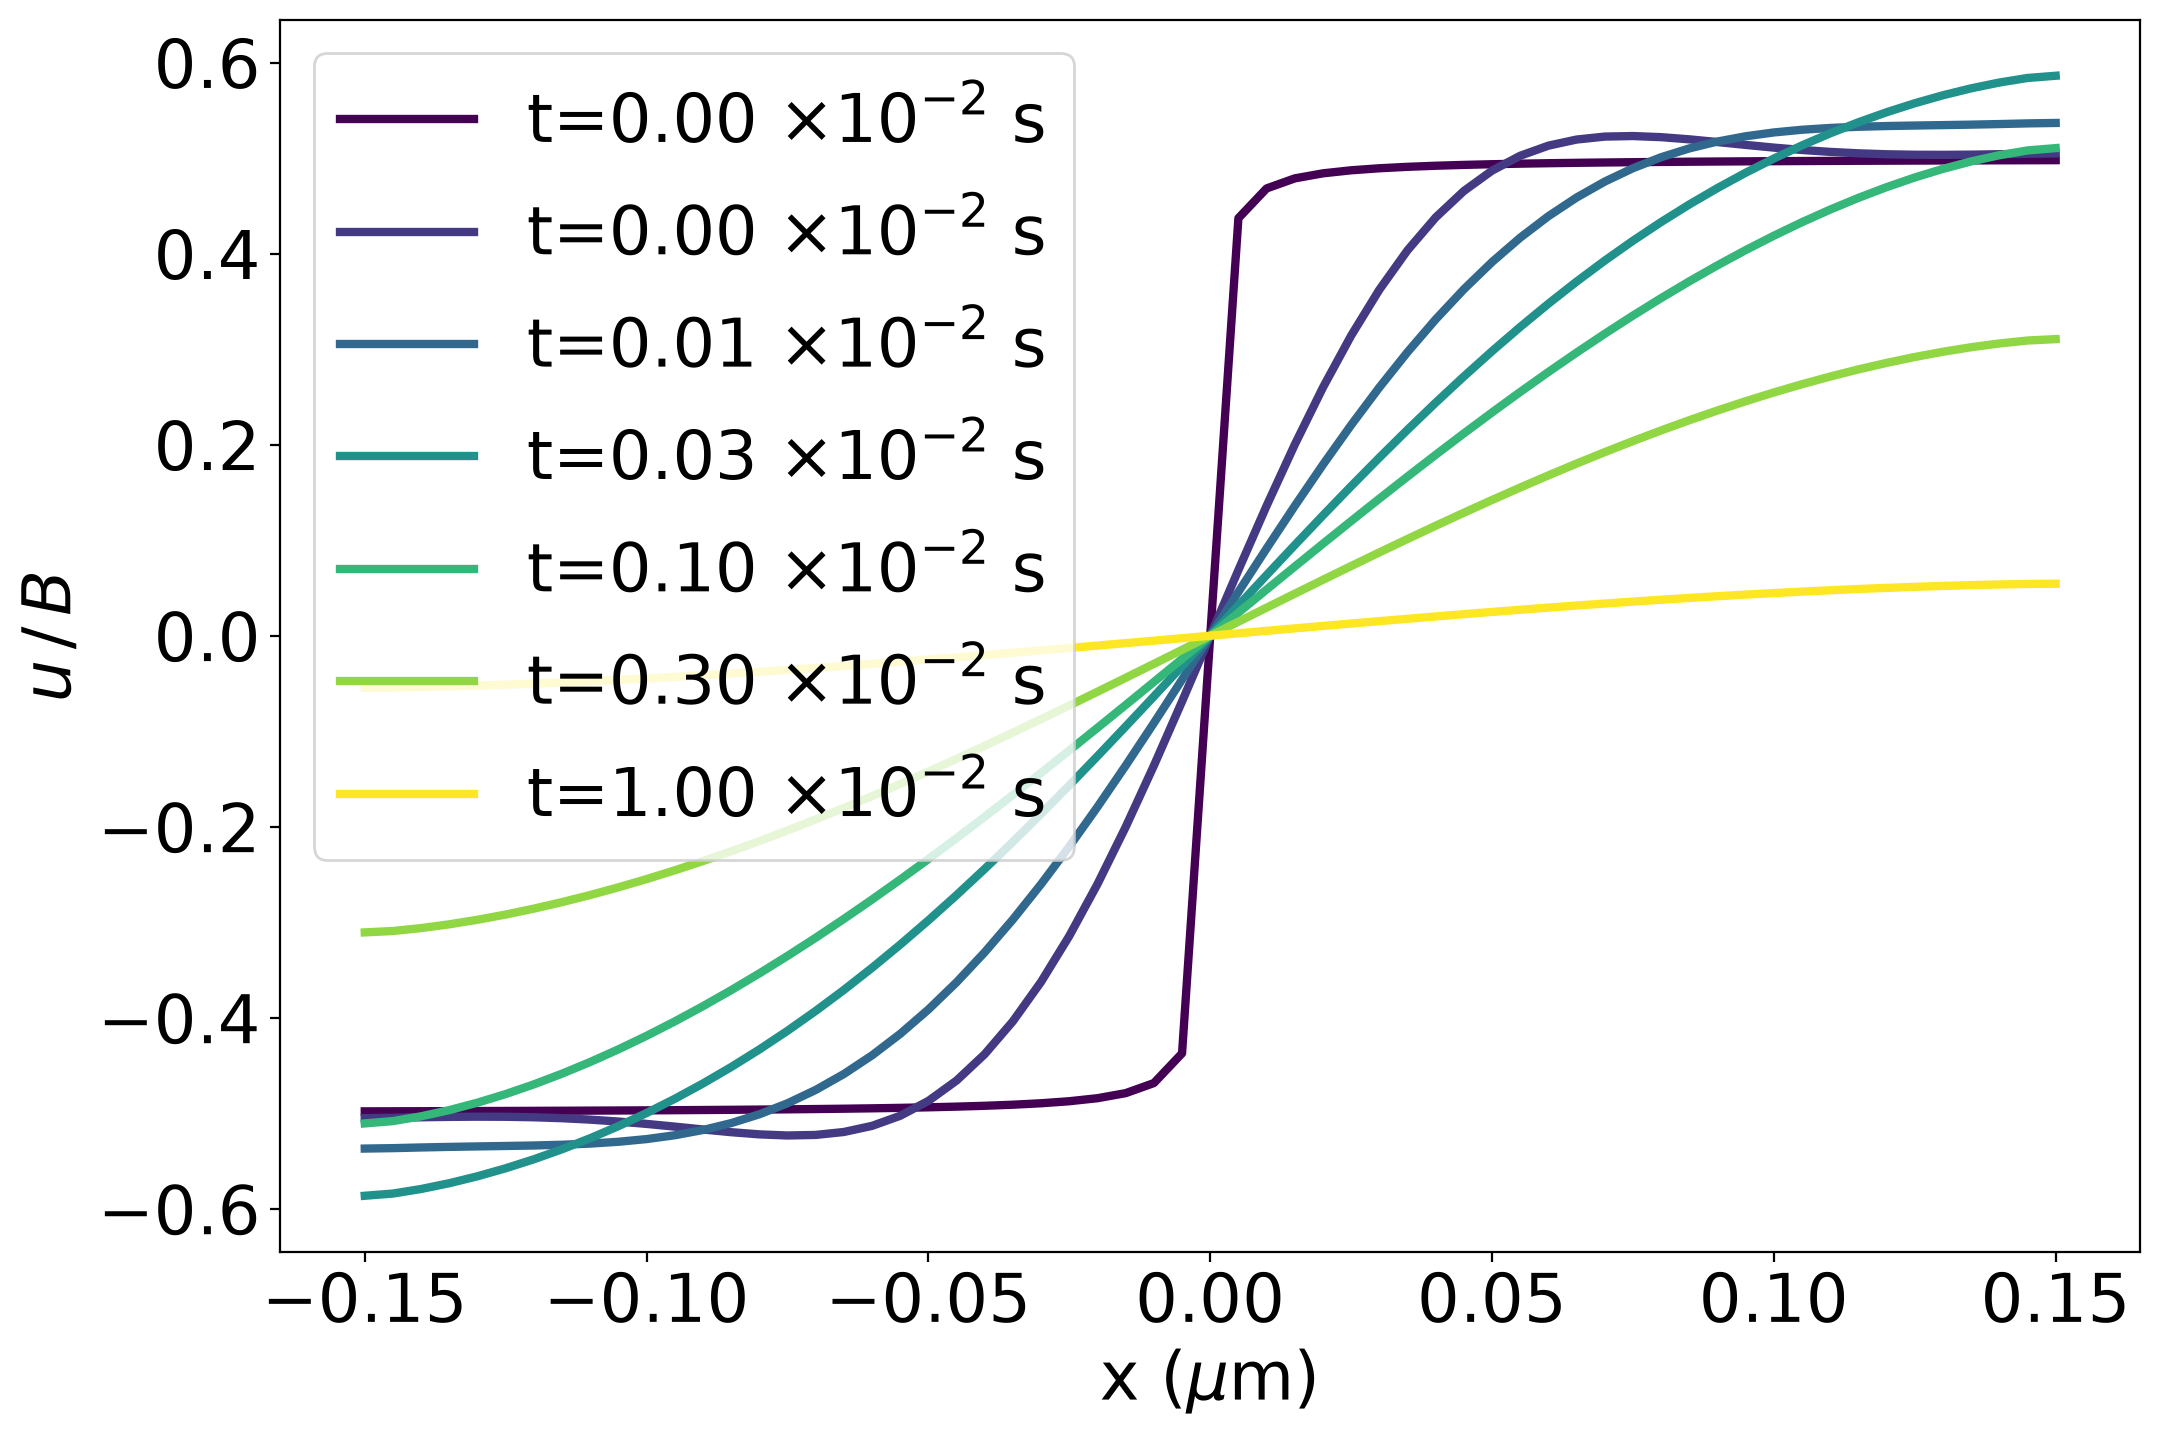

In [10]:
t_ = [1.e-5, 3.e-5, 1.e-4, 3.e-4, 1.e-3, 3.e-3, 1.e-2]
gbdd.plot_field('bfield', 
                times=t_,
                lw=3,
                #file='F4a_bfield_gb01_t600.pdf'
               )
gbdd.plot_field('beta', 
                times=t_,
                lw=3,
                #file='F4a_bfield_gb01_t600.pdf'
               )
gbdd.plot_field('flux', 
                times=t_,
                lw=3,
                #file='F4b_flux_gb01_t600.pdf'
               )
gbdd.plot_field('displacement', 
                times=t_,
                lw=3,
                #file='F4c_displacement_gb01_t600.pdf'
               )

In [ ]:
print(gbdd.lambda_)